In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("C:\customer_churn_analysis\data\Customer_Churn.csv")

In [3]:
print("dataset shape:",df.shape)
display(df.head())
df.info

dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<bound method DataFrame.info of       customerID  gender  SeniorCitizen Partner Dependents  tenure  \
0     7590-VHVEG  Female              0     Yes         No       1   
1     5575-GNVDE    Male              0      No         No      34   
2     3668-QPYBK    Male              0      No         No       2   
3     7795-CFOCW    Male              0      No         No      45   
4     9237-HQITU  Female              0      No         No       2   
...          ...     ...            ...     ...        ...     ...   
7038  6840-RESVB    Male              0     Yes        Yes      24   
7039  2234-XADUH  Female              0     Yes        Yes      72   
7040  4801-JZAZL  Female              0     Yes        Yes      11   
7041  8361-LTMKD    Male              1     Yes         No       4   
7042  3186-AJIEK    Male              0      No         No      66   

     PhoneService     MultipleLines InternetService OnlineSecurity  ...  \
0              No  No phone service             DSL 

In [5]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

## Data Cleaning

In [9]:
print("shape:" ,df.shape)
print("duplicates:",df.duplicated().sum())
print("missing values:")
print(df.isnull().sum())

print("unique customer IDs:",df["customerID"].nunique)
print(df["Churn"].value_counts(dropna = False))

shape: (7043, 21)
duplicates: 0
missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
unique customer IDs: <bound method IndexOpsMixin.nunique of 0       7590-VHVEG
1       5575-GNVDE
2       3668-QPYBK
3       7795-CFOCW
4       9237-HQITU
           ...    
7038    6840-RESVB
7039    2234-XADUH
7040    4801-JZAZL
7041    8361-LTMKD
7042    3186-AJIEK
Name: customerID, Length: 7043, dtype: object>
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [10]:
df = df.copy()

df.columns = df.columns.str.strip()
for col in df.select_dtypes(include = "object").columns:
    df[col] = df[col] .str.strip()

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"] , errors = "coerce"
)

print("duplicate customer IDs:" , df["customerID"].duplicated().sum())

print(df.isnull().sum()[df.isnull().sum() > 0 ])

display(df[df["TotalCharges"].isna()])

duplicate customer IDs: 0
TotalCharges    11
dtype: int64


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [11]:
df.loc[
    df["TotalCharges"].isna() & (df["tenure"] == 0 ),
    "TotalCharges"
    ] = 0

print(df.isnull().sum())
print("final shape:", df.shape)

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
final shape: (7043, 21)


In [12]:
from pathlib import Path

Path("../data").mkdir(
    parents=True, exist_ok=True
)

df.to_csv(
    "../data/customer_churn_cleaned.csv",
    index=False
)

## Exploratory Data Analysis and visualization

In [13]:
from pathlib import Path

project_dir = Path(r"C:\customer_churn_analysis\outputs")
output_dir = project_dir / "outputs"

output_dir.mkdir(parents=True, exist_ok=True)

print("Charts will be saved in:", output_dir)

Charts will be saved in: C:\customer_churn_analysis\outputs\outputs


### Overall churn rate

overall churn rate:  26.54%


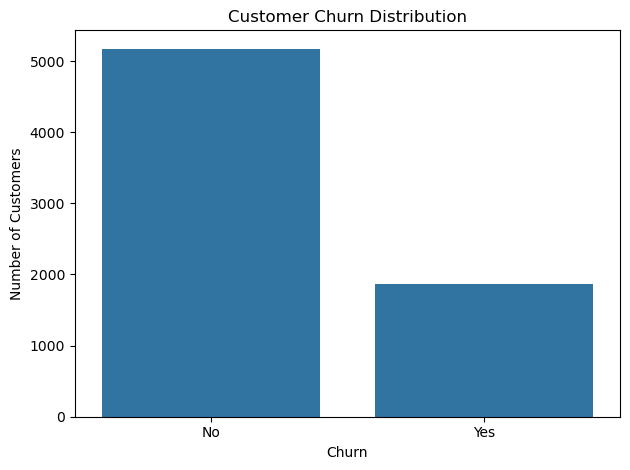

In [14]:
churn_rate = df["Churn"].eq("Yes").mean() * 100

print(f"overall churn rate: {churn_rate: .2f}%")

sns.countplot(data = df, x = "Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig(
    output_dir / "Customer_churn_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



### Churn by contract type

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


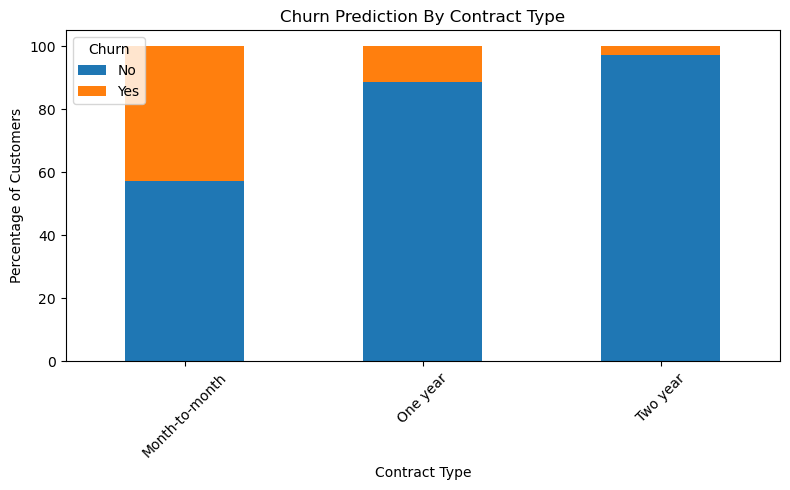

In [15]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize = "index"
)*100

display(contract_churn)

contract_churn.plot(
    kind = "bar",
    stacked = True,
    figsize = (8,5)
)
plt.title("Churn Prediction By Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation =45)
plt.tight_layout()
plt.savefig(
    output_dir / "contract_churn.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



### Tenure and churn

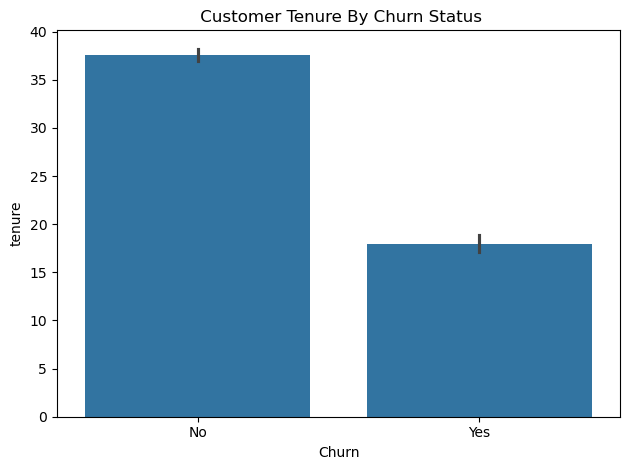

In [16]:
sns.barplot(
    data = df,
    x = "Churn",
    y = "tenure"
)
plt.title(" Customer Tenure By Churn Status")
plt.tight_layout()
plt.savefig(
    output_dir / "customer_tenure_churn.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Monthly charges and churn

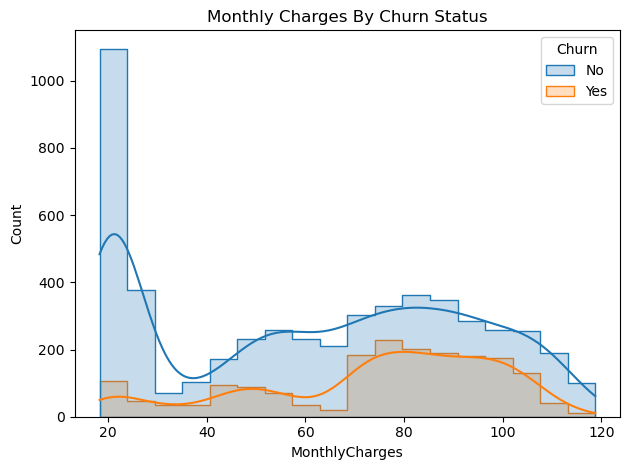

In [17]:
sns.histplot(
    data = df,
    x = "MonthlyCharges",
    hue = "Churn",
    kde = True,
    element = "step"
)
plt.title("Monthly Charges By Churn Status")
plt.tight_layout()
plt.savefig(
    output_dir / "monthly_charges_churn.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()   

### Churn by payment method

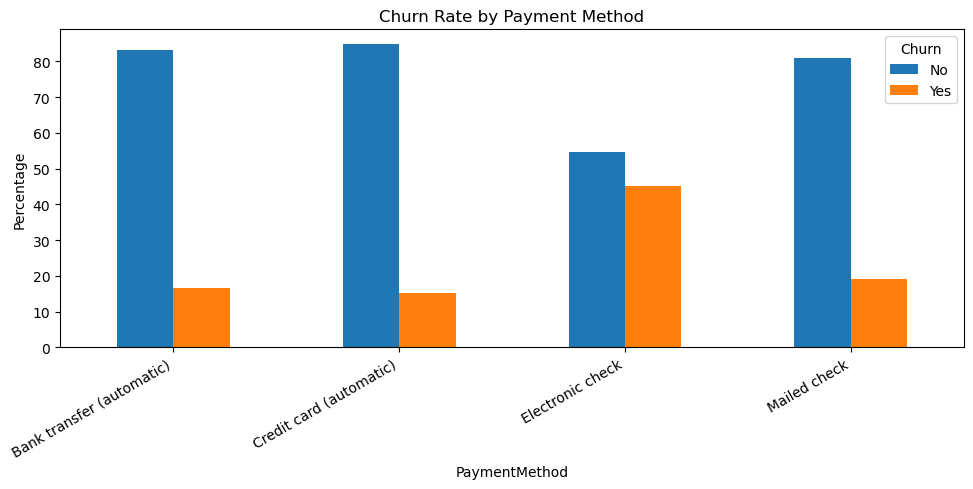

In [18]:
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize = "index"
)*100

payment_churn.plot(
    kind = "bar",
    figsize = (10,5)
)
plt.title("Churn Rate by Payment Method")
plt.ylabel("Percentage")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(
    output_dir / "payment_method_churn.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Correlation between numerical variables

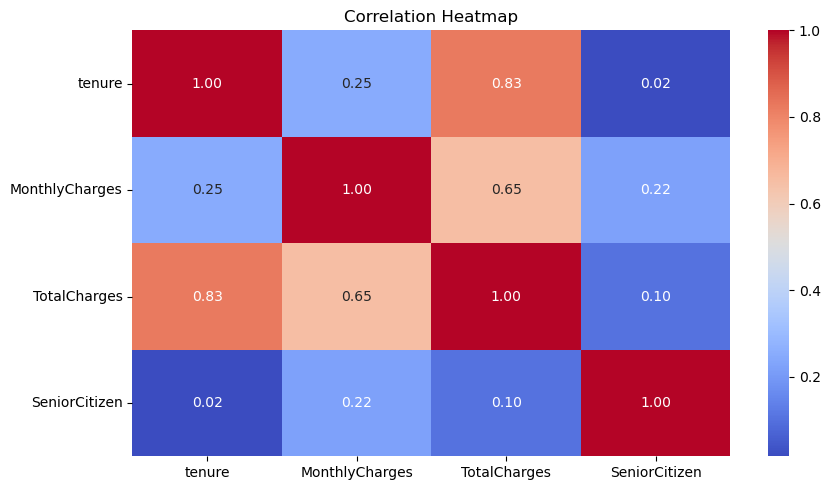

In [19]:
numeric_cols =[
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "SeniorCitizen"
]
plt.figure(figsize = (9,5))

sns.heatmap(
    df[numeric_cols].corr(),
    annot = True,
    cmap = "coolwarm",
    fmt = ".2f"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig(
    output_dir / "correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## statistical analysis

In [20]:
from scipy.stats import chi2_contingency

contingency_table = pd.crosstab(
    df["Contract"],
    df["Churn"]
)

chi2,p_value,dof,expected = chi2_contingency(
    contingency_table
)
print("chi-square statistics:", chi2)
print("degrees of freedom:" , dof)
print("P-value:", p_value)

if p_value < 0.05:
    print("there is evidence of an association")
else:
    print("Insufficient evidence of an association.")

chi-square statistics: 1184.5965720837926
degrees of freedom: 2
P-value: 5.863038300673391e-258
there is evidence of an association


# machine learning model

## Prepare the features

In [21]:
from sklearn.model_selection import train_test_split

In [34]:
x = df.drop(columns=["Churn", "customerID"])
y = df["Churn"].map({"No": 0, "Yes": 1})

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

numeric_features = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

categorical_features = [
    col for col in x.columns
    if col not in numeric_features
]

print("Training rows:", x_train.shape[0])
print("Testing rows:", x_test.shape[0])

Training rows: 5634
Testing rows: 1409


## processing pipeline

In [35]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

In [36]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

logistic_model.fit(x_train, y_train)

print("Training completed.")

Training completed.


## compare models

In [37]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
     accuracy_score,
     precision_score,
     recall_score,
     f1_score,
     roc_auc_score
)

In [39]:
models = {
    "Logistic Regression": logistic_model,

    "Decision Tree": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            max_depth=6,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            min_samples_leaf=3,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ])
}

results = []

for name, model in models.items():
    model.fit(x_train, y_train)

    predictions = model.predict(x_test)
    probabilities = model.predict_proba(x_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results).sort_values(
    "ROC-AUC", ascending=False
)

display(results_df)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.738112,0.504303,0.783422,0.613613,0.841639
2,Random Forest,0.777147,0.566079,0.687166,0.620773,0.837808
1,Decision Tree,0.740241,0.506873,0.788770,0.617155,0.828417


## final model

selected model: Logistic Regression
              precision    recall  f1-score   support

    no Churn       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



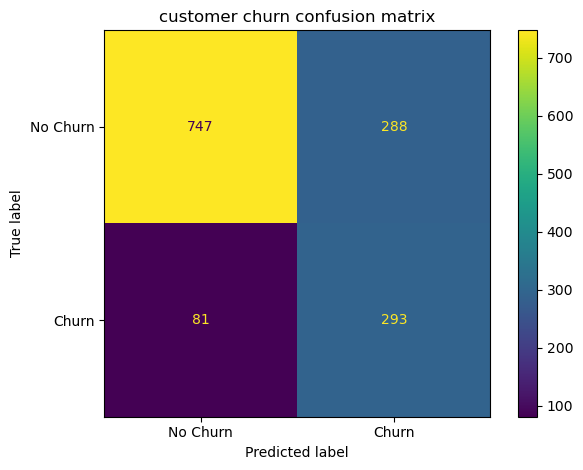

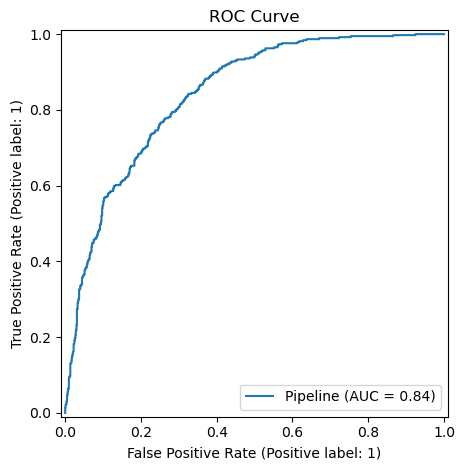

In [45]:
from sklearn.metrics import (
ConfusionMatrixDisplay,
classification_report,
RocCurveDisplay
)

best_model_name = results_df.iloc[0]["Model"]
best_model = models[best_model_name]

print("selected model:" , best_model_name)

predictions = best_model.predict(x_test)

print(classification_report(
    y_test,
    predictions,
    target_names = ["no Churn", "Churn"]
))

ConfusionMatrixDisplay.from_estimator(
    best_model,x_test,y_test,
    display_labels= ["No Churn", "Churn"]
)

plt.title("customer churn confusion matrix")
plt.tight_layout()
plt.savefig(
    output_dir / "customer_churn_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

RocCurveDisplay.from_estimator(
    best_model,x_test, y_test
)
plt.title("ROC Curve")
plt.tight_layout()
plt.savefig(
    output_dir / "roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [47]:
import sklearn
import sys

print("Scikit-learn:", sklearn.__version__)
print("Python path:", sys.executable)

Scikit-learn: 1.7.2
Python path: C:\ProgramData\anaconda3\python.exe


In [46]:
import joblib
from pathlib import Path

Path("models").mkdir(exist_ok=True)

joblib.dump(
    best_model,
    "models/churn_model.joblib"
)

['models/churn_model.joblib']